# Geometry from organ masks: a toy example

This notebook shows, on a tiny 6 x 6 example, how we turn **organ masks** into the four geometry
features used by the geometry bias in our model:

| Feature | Question | How it is computed |
|---|---|---|
| center | where is the organ? | mean position of the voxels equal to 1, in mm |
| volume | how big is it? | number of voxels equal to 1 x size of one voxel |
| touching | are two organs neighbors? | grow mask A by one voxel (binary dilation); does it overlap mask B? |
| distance | how far apart are they? | Euclidean distance between the two centers |

The real pipeline does the same on 3D masks (about 330 x 330 x 60 voxels, 9 regions per scan,
masks from RadGenome-ChestCT made with SAT).

### 1. Two toy masks
A mask has the same size as the image: 1 = inside the organ, 0 = outside. Here one voxel is 1 mm x 1 mm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

spacing = np.array([1.0, 1.0])     # size of one voxel in mm (row, column)

heart = np.array([
    [0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
], dtype=bool)

lung = np.array([
    [0, 0, 0, 0, 0, 0],
    [1, 1, 0, 0, 0, 0],
    [1, 1, 0, 0, 0, 0],
    [1, 1, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
], dtype=bool)

print("heart voxels:", heart.sum())
print("lung voxels :", lung.sum())

heart voxels: 4
lung voxels : 6


### 2. Center and volume
The same two functions are applied to every organ.

In [2]:
def center_mm(mask, spacing):
    """Mean position (row, column) of the voxels equal to 1, in mm."""
    positions = np.argwhere(mask)              # one (row, column) per voxel equal to 1
    return positions.mean(axis=0) * spacing


def volume(mask, spacing):
    """Number of voxels equal to 1 times the size of one voxel (mm^2 here, mm^3 in 3D)."""
    return mask.sum() * np.prod(spacing)


heart_center = center_mm(heart, spacing)
lung_center = center_mm(lung, spacing)

print("heart center (y, x):", heart_center, "| size:", volume(heart, spacing), "mm^2")
print("lung center  (y, x):", lung_center, "| size:", volume(lung, spacing), "mm^2")

heart center (y, x): [2.5 2.5] | size: 4.0 mm^2
lung center  (y, x): [2.  0.5] | size: 6.0 mm^2


Check by hand:

- heart voxels are at (y, x) = (2,2), (2,3), (3,2), (3,3) → center = (2.5, 2.5), size = 4
- lung voxels are in columns 0-1, rows 1-3 → center = (2.0, 0.5), size = 6

### 3. Touching
Two masks never overlap, even when the organs are direct neighbors. So we **grow** one mask by one voxel
(binary dilation, a morphological operation) and check whether it now overlaps the other mask.

`scipy.ndimage.binary_dilation` uses a cross-shaped structuring element by default
(4 neighbors in 2D, 6 neighbors in 3D).

In [3]:
def touching(mask_a, mask_b):
    """True if mask_a, grown by one voxel, overlaps mask_b."""
    grown = ndimage.binary_dilation(mask_a)
    return bool((grown & mask_b).any())


heart_grown = ndimage.binary_dilation(heart)
print(heart_grown.astype(int))
print("heart touches lung:", touching(heart, lung))

# a far-away organ, to show the other case
thyroid = np.zeros((6, 6), dtype=bool)
thyroid[0, 5] = True
print("heart touches thyroid:", touching(heart, thyroid))

[[0 0 0 0 0 0]
 [0 0 1 1 0 0]
 [0 1 1 1 1 0]
 [0 1 1 1 1 0]
 [0 0 1 1 0 0]
 [0 0 0 0 0 0]]
heart touches lung: True
heart touches thyroid: False


### 4. Distance
Euclidean distance between the two centers.

In [4]:
def distance_mm(center_a, center_b):
    return np.linalg.norm(center_a - center_b)


thyroid_center = center_mm(thyroid, spacing)

print(f"heart - lung   : {distance_mm(heart_center, lung_center):.2f} mm")
print(f"heart - thyroid: {distance_mm(heart_center, thyroid_center):.2f} mm")

heart - lung   : 2.06 mm
heart - thyroid: 3.54 mm


Check by hand: heart - lung = sqrt((2.5 - 2.0)^2 + (2.5 - 0.5)^2) = sqrt(4.25) = 2.06 mm

### 5. Picture
Heart, lung and thyroid masks, their centers, and the grown heart mask (outline).

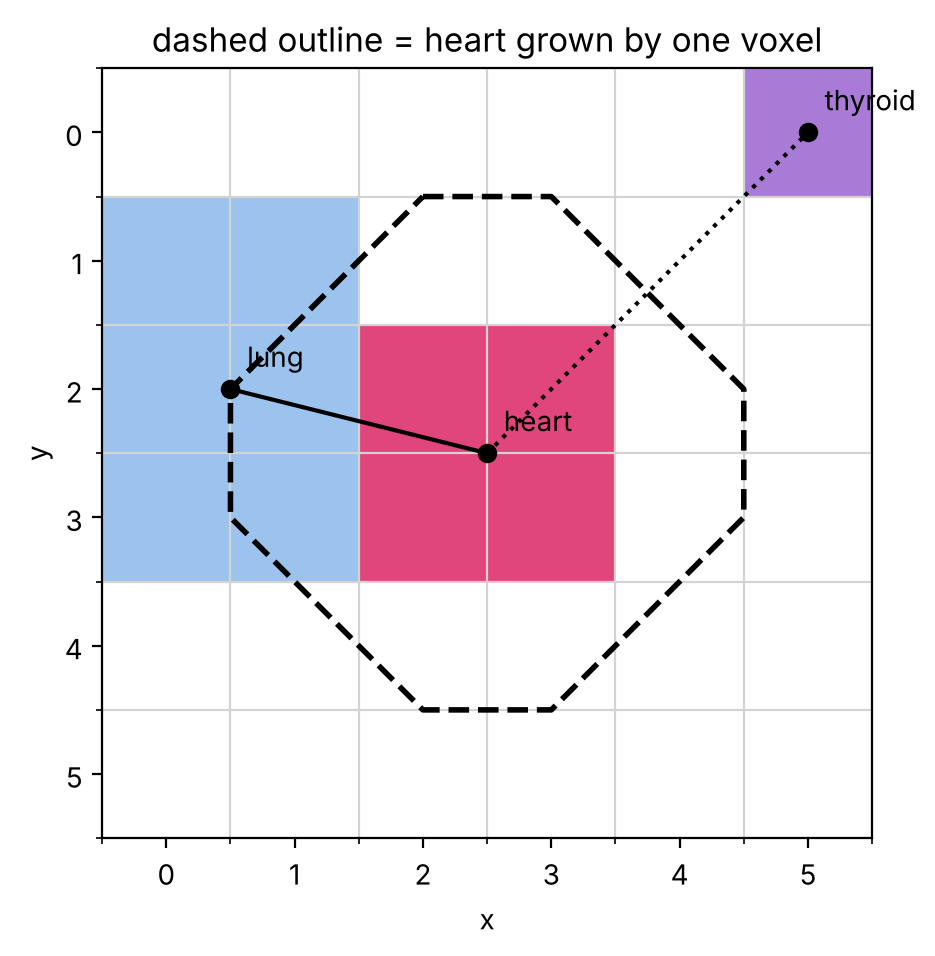

In [5]:
image = np.zeros((6, 6))
image[lung] = 1
image[heart] = 2
image[thyroid] = 3

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image, cmap=plt.matplotlib.colors.ListedColormap(["white", "#9CC3EE", "#E0457B", "#A97BD6"]))

# grid lines
ax.set_xticks(np.arange(-0.5, 6), minor=True)
ax.set_yticks(np.arange(-0.5, 6), minor=True)
ax.grid(which="minor", color="lightgray")

# outline of the grown heart mask
ax.contour(heart_grown, levels=[0.5], colors="black", linewidths=2, linestyles="dashed")

# centers and the two distances
for name, c in [("heart", heart_center), ("lung", lung_center), ("thyroid", thyroid_center)]:
    ax.plot(c[1], c[0], "ko")
    ax.annotate(name, (c[1], c[0]), textcoords="offset points", xytext=(6, 8))
ax.plot([heart_center[1], lung_center[1]], [heart_center[0], lung_center[0]], "k-")
ax.plot([heart_center[1], thyroid_center[1]], [heart_center[0], thyroid_center[0]], "k:")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("dashed outline = heart grown by one voxel")
plt.show()

### 6. How the model uses these numbers
For organs *i* and *j*, the geometry bias added to the attention score is

`bias(i, j) = - w * distance(i, j) + b * touching(i, j)`

where `w` and `b` are learned for each attention head. The values below are only an illustration
with fixed `w` and `b`.

In [6]:
w, b = 0.5, 1.0      # illustration only; in the model these are learned

pairs = {
    "heart - lung": (distance_mm(heart_center, lung_center), touching(heart, lung)),
    "heart - thyroid": (distance_mm(heart_center, thyroid_center), touching(heart, thyroid)),
}

for name, (dist, touch) in pairs.items():
    bias = -w * dist + b * touch
    print(f"{name:<16} distance {dist:.2f}  touching {int(touch)}  bias {bias:+.2f}")

heart - lung     distance 2.06  touching 1  bias -0.03
heart - thyroid  distance 3.54  touching 0  bias -1.77


The touching, nearby organ (lung) gets a higher bias than the distant one (thyroid),
so the heart token attends more to its neighbor.

**In the real pipeline:** the same computations run in 3D with the true voxel size of each scan (mm),
for 9 regions per scan (the RadGenome pleura mask is identical to the lung mask, so it is dropped),
and are saved once per split as `geometry_<split>.npz`.